# Nairobi Delivery Time Prediction — Multivariate Regression

**Mission:** Make last-mile delivery reliable and affordable across East Africa so small businesses can grow.

**Use case:** Predict how long a motorbike delivery in Nairobi will take, from the moment the rider picks up the parcel to arrival at the customer (in minutes).

**Who uses the prediction and for what:** Delivery platforms such as Sendy show this estimate to the business and its customer as an accurate arrival time, and use it to plan which rider takes which order. Accurate ETAs build trust and cut wasted waiting time.

**Dataset:** Sendy Logistics Challenge (Zindi) — 21,201 real, anonymised Nairobi orders plus statistics for 960 riders.
Source: https://zindi.africa/competitions/sendy-logistics-challenge/data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## 1. Load and merge the data
The orders file and the riders file share the `Rider Id` column, so each order gets its rider's experience and rating attached.

In [2]:
orders = pd.read_csv("Train.csv")
riders = pd.read_csv("Riders.csv")

# Each order has a Rider Id, so we attach that rider's statistics to the order
df = orders.merge(riders, on="Rider Id", how="left")

print("Orders:", orders.shape)
print("Riders:", riders.shape)
print("Merged:", df.shape)
print("Orders with no matching rider:", df["No_Of_Orders"].isna().sum())

Orders: (21201, 29)
Riders: (960, 5)
Merged: (21201, 33)
Orders with no matching rider: 0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21201 entries, 0 to 21200
Data columns (total 33 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Order No                                   21201 non-null  str    
 1   User Id                                    21201 non-null  str    
 2   Vehicle Type                               21201 non-null  str    
 3   Platform Type                              21201 non-null  int64  
 4   Personal or Business                       21201 non-null  str    
 5   Placement - Day of Month                   21201 non-null  int64  
 6   Placement - Weekday (Mo = 1)               21201 non-null  int64  
 7   Placement - Time                           21201 non-null  str    
 8   Confirmation - Day of Month                21201 non-null  int64  
 9   Confirmation - Weekday (Mo = 1)            21201 non-null  int64  
 10  Confirmation - Time              

In [4]:
missing = df.isna().sum()
print((missing[missing > 0] / len(df) * 100).round(1).astype(str) + " % missing")
print()
print(df["Vehicle Type"].value_counts())
print()
print(df["Platform Type"].value_counts())
print()
print(df["Personal or Business"].value_counts())

Temperature                     20.6 % missing
Precipitation in millimeters    97.4 % missing
dtype: str

Vehicle Type
Bike    21201
Name: count, dtype: int64

Platform Type
3    18054
1     2147
2      980
4       20
Name: count, dtype: int64

Personal or Business
Business    17384
Personal     3817
Name: count, dtype: int64


**What this shows:** Precipitation is 97% missing and Temperature 21% missing. Every order uses a bike, so `Vehicle Type` carries no information. Note also that the rider column `Age` means *days since the rider's first delivery* (experience), not the rider's age in years.

## 2. Feature engineering: new columns
- **Pickup Hour** is pulled from the pickup time, because traffic in Nairobi depends on the time of day.
- **Delivery Time (min)** is the target, converted from seconds to minutes so the errors are easy to read.

In [5]:
# Pickup hour: the time of day the rider collected the parcel (rush hour vs quiet hours)
df["Pickup Hour"] = pd.to_datetime(df["Pickup - Time"], format="%I:%M:%S %p").dt.hour

# Target in minutes instead of seconds, so errors are easier to read
df["Delivery Time (min)"] = df["Time from Pickup to Arrival"] / 60

df[["Pickup - Time", "Pickup Hour", "Time from Pickup to Arrival", "Delivery Time (min)"]].head()

,Pickup - Time,Pickup Hour,Time from Pickup to Arrival,Delivery Time (min)
0,10:27:30 AM,10,745,12.416667
1,11:44:09 AM,11,1993,33.216667
2,12:53:03 PM,12,455,7.583333
3,9:43:06 AM,9,1341,22.350000
4,10:05:23 AM,10,1214,20.233333


## 3. Exploratory data analysis
### Visualization 1: Distribution of the target

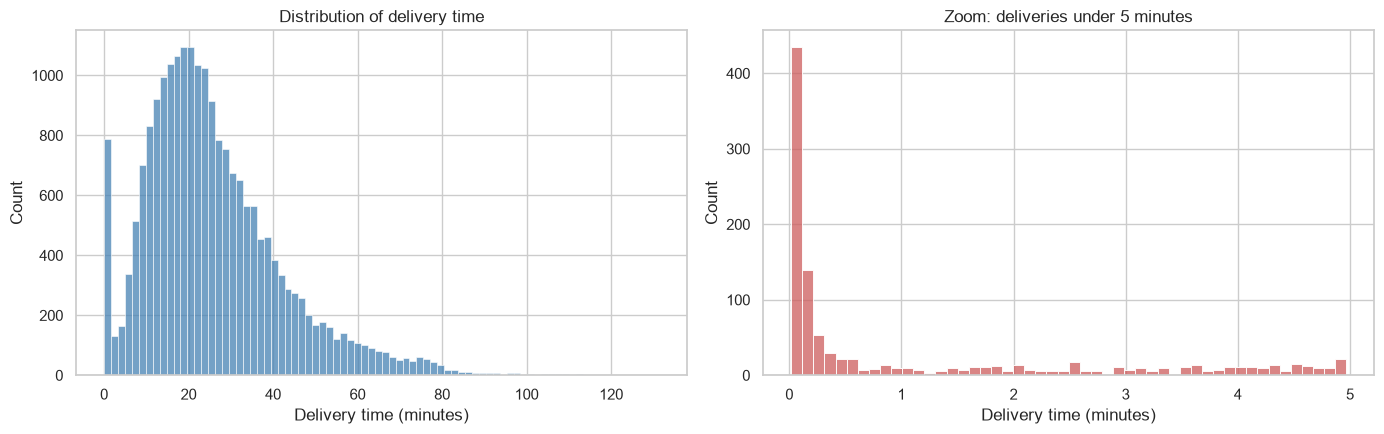

Deliveries under 1 minute: 740


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(df["Delivery Time (min)"], bins=80, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of delivery time")
axes[0].set_xlabel("Delivery time (minutes)")

sns.histplot(df.loc[df["Delivery Time (min)"] < 5, "Delivery Time (min)"], bins=50, ax=axes[1], color="indianred")
axes[1].set_title("Zoom: deliveries under 5 minutes")
axes[1].set_xlabel("Delivery time (minutes)")

plt.tight_layout()
plt.show()

print("Deliveries under 1 minute:", (df["Delivery Time (min)"] < 1).sum())

**What it shows:** Most deliveries take 10–40 minutes (median ≈ 23 min) with a long right tail up to about 2 hours. There is also an unrealistic spike close to 0 minutes: 740 orders were "delivered" in under 1 minute, which is impossible across Nairobi. These are riders tapping *arrived* by mistake.

**Decision:** Remove the 740 orders under 1 minute, because they are data-entry errors that would teach the model wrong patterns. The long right tail is real (traffic, long trips), so it stays.

In [7]:
before = len(df)
df = df[df["Delivery Time (min)"] >= 1].copy()
print(f"Removed {before - len(df)} impossible deliveries. Rows left: {len(df)}")

Removed 740 impossible deliveries. Rows left: 20461


### Visualization 2: Correlation heatmap

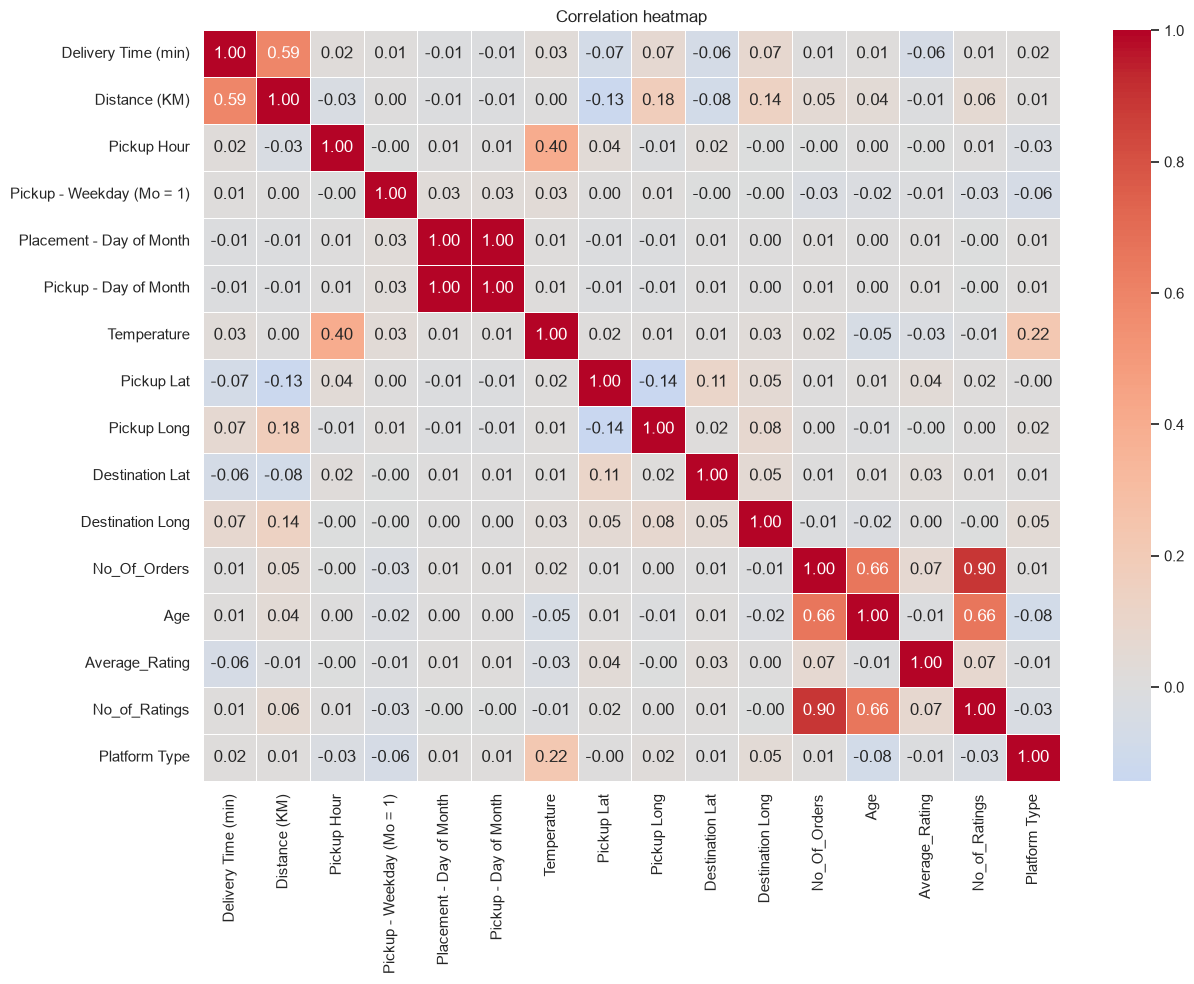

Distance (KM)                0.586
Destination Long             0.072
Pickup Long                  0.069
Pickup Lat                  -0.068
Destination Lat             -0.063
Average_Rating              -0.062
Temperature                  0.027
Pickup Hour                  0.020
Platform Type                0.015
Age                          0.014
Placement - Day of Month    -0.014
Pickup - Day of Month       -0.014
Pickup - Weekday (Mo = 1)    0.009
No_of_Ratings                0.009
No_Of_Orders                 0.005
Name: Delivery Time (min), dtype: float64


In [8]:
corr_cols = [
    "Delivery Time (min)", "Distance (KM)", "Pickup Hour", "Pickup - Weekday (Mo = 1)",
    "Placement - Day of Month", "Pickup - Day of Month", "Temperature",
    "Pickup Lat", "Pickup Long", "Destination Lat", "Destination Long",
    "No_Of_Orders", "Age", "Average_Rating", "No_of_Ratings", "Platform Type",
]
corr = df[corr_cols].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

print(corr["Delivery Time (min)"].drop("Delivery Time (min)").sort_values(key=abs, ascending=False).round(3))

**What it shows:** **Distance (KM)** is by far the strongest predictor of delivery time (r ≈ 0.59). Every other column has a weak *linear* correlation (|r| < 0.08). `No_Of_Orders` and `No_of_Ratings` are strongly correlated with each other (r ≈ 0.90), so they carry the same information. `Placement - Day of Month` and `Pickup - Day of Month` are identical copies (r = 1.00).

**Decisions:**
- Distance is the key feature, and it will be used for the before/after scatter plots.
- Drop `No_of_Ratings` (it duplicates `No_Of_Orders`) and all the repeated day/weekday columns, keeping only `Pickup - Weekday`.
- Keep the coordinates, pickup hour and rider stats even though their linear correlation is weak: traffic zones and rush hours affect time *non-linearly*, which tree models can still learn.
- Drop `Temperature`: 21% missing and almost no relationship with the target (r ≈ 0.03).

### Visualization 3: Distance distribution and categorical features

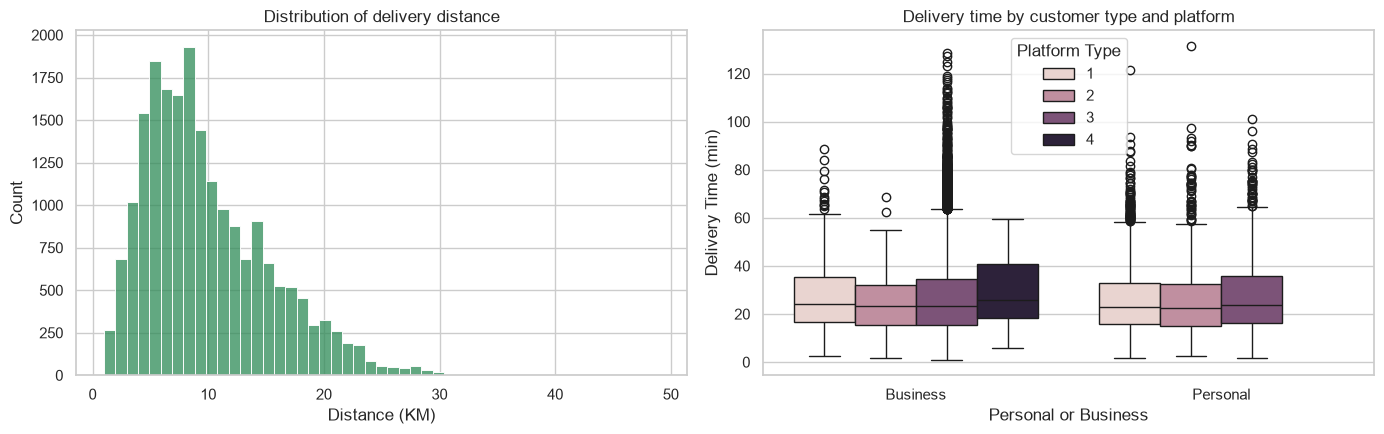

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(df["Distance (KM)"], bins=49, ax=axes[0], color="seagreen")
axes[0].set_title("Distribution of delivery distance")

sns.boxplot(data=df, x="Personal or Business", y="Delivery Time (min)", hue="Platform Type", ax=axes[1])
axes[1].set_title("Delivery time by customer type and platform")

plt.tight_layout()
plt.show()

**What it shows:** Most trips are 3–15 km, with a few up to 49 km, all realistic for Nairobi. The categorical columns shift delivery time only slightly: platform 4 orders take a little longer, and business and personal orders are similar.

**Decision:** Keep `Platform Type` and `Personal or Business` as categorical features (converted to numbers with one-hot encoding). The effect is small but real, and it costs the model almost nothing to include them. Distance values are realistic, which later guides the API range (1–50 km).

## 4. Feature selection summary

| Dropped column(s) | Reason |
|---|---|
| Order No, User Id, Rider Id | Identifiers, no predictive meaning |
| Vehicle Type | Only one value (Bike) |
| Arrival at Destination (day, weekday, time) | **Data leakage**: these reveal the answer |
| Placement / Confirmation / Arrival at Pickup columns | Their day and weekday are copies of the pickup ones (r = 1.00), and their times describe steps before the trip starts |
| Pickup - Day of Month, Pickup - Time | Day of month has no link to delivery time (r = −0.01); the time is replaced by the engineered Pickup Hour |
| Precipitation in millimeters | 97% missing |
| Temperature | 21% missing, no correlation with the target |
| No_of_Ratings | Duplicates No_Of_Orders (r = 0.90) |
| Time from Pickup to Arrival | Original target in seconds (replaced by minutes) |

**Features kept (12):** Distance, Pickup Weekday, Pickup Hour, Pickup Lat/Long, Destination Lat/Long, rider No_Of_Orders, rider Age (days active), rider Average_Rating, Platform Type, Personal or Business. **Distance matters most.**

In [10]:
numeric_features = [
    "Distance (KM)", "Pickup - Weekday (Mo = 1)", "Pickup Hour",
    "Pickup Lat", "Pickup Long", "Destination Lat", "Destination Long",
    "No_Of_Orders", "Age", "Average_Rating",
]
categorical_features = ["Platform Type", "Personal or Business"]
features = numeric_features + categorical_features
target = "Delivery Time (min)"

X = df[features]
y = df[target]

print("Features used:", len(features))
print(X.dtypes)
X.head()

Features used: 12
Distance (KM)                  int64
Pickup - Weekday (Mo = 1)      int64
Pickup Hour                    int32
Pickup Lat                   float64
Pickup Long                  float64
Destination Lat              float64
Destination Long             float64
No_Of_Orders                   int64
Age                            int64
Average_Rating               float64
Platform Type                  int64
Personal or Business             str
dtype: object


,Distance (KM),Pickup - Weekday (Mo = 1),Pickup Hour,Pickup Lat,Pickup Long,Destination Lat,Destination Long,No_Of_Orders,Age,Average_Rating,Platform Type,Personal or Business
0,4,5,10,-1.317755,36.830370,-1.300406,36.829741,1637,1309,13.8,3,Business
1,16,5,11,-1.351453,36.899315,-1.295004,36.814358,396,339,13.6,3,Personal
2,3,2,12,-1.308284,36.843419,-1.300921,36.828195,1023,242,12.5,3,Business
3,9,5,9,-1.281301,36.832396,-1.257147,36.795063,886,283,14.5,3,Business
4,9,1,10,-1.266597,36.792118,-1.295041,36.809817,2311,872,14.1,1,Personal


## 5. Encode categorical columns, split, then standardize
- **One-hot encoding** turns `Platform Type` (1–4) and `Personal or Business` into 0/1 columns, so the models only see numbers.
- **Split first (80% train / 20% test), then scale.** The scaler is fitted on the **training set only** and then applied to the test set. If it also learned the mean and standard deviation of the test data, information from the "exam" would leak into training and the test MSE would look better than it really is.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

X_train_prep = preprocessor.fit_transform(X_train)   # learns mean/std and categories from TRAIN only
X_test_prep = preprocessor.transform(X_test)          # re-uses what it learned, never looks at test

encoded_names = preprocessor.get_feature_names_out()
print("Train:", X_train.shape, "->", X_train_prep.shape)
print("Test: ", X_test.shape, "->", X_test_prep.shape)
print("Columns after encoding:", list(encoded_names))
pd.DataFrame(X_train_prep[:5], columns=encoded_names).round(2)

Train: (16368, 12) -> (16368, 16)
Test:  (4093, 12) -> (4093, 16)
Columns after encoding: ['num__Distance (KM)', 'num__Pickup - Weekday (Mo = 1)', 'num__Pickup Hour', 'num__Pickup Lat', 'num__Pickup Long', 'num__Destination Lat', 'num__Destination Long', 'num__No_Of_Orders', 'num__Age', 'num__Average_Rating', 'cat__Platform Type_1', 'cat__Platform Type_2', 'cat__Platform Type_3', 'cat__Platform Type_4', 'cat__Personal or Business_Business', 'cat__Personal or Business_Personal']


,num__Distance (KM),num__Pickup - Weekday (Mo = 1),num__Pickup Hour,num__Pickup Lat,num__Pickup Long,num__Destination Lat,num__Destination Long,num__No_Of_Orders,num__Age,num__Average_Rating,cat__Platform Type_1,cat__Platform Type_2,cat__Platform Type_3,cat__Platform Type_4,cat__Personal or Business_Business,cat__Personal or Business_Personal
0,-0.99,-1.44,0.06,-0.93,0.86,-0.63,0.22,-0.14,0.22,0.23,1.0,0.0,0.0,0.0,0.0,1.0
1,-0.11,-0.16,-0.34,0.57,-0.48,-0.51,0.41,-0.99,-1.15,1.19,0.0,0.0,1.0,0.0,1.0,0.0
2,-0.11,0.48,-0.73,0.85,-0.77,-0.14,-1.35,-0.05,0.15,-0.63,0.0,0.0,1.0,0.0,1.0,0.0
3,-0.99,-0.16,-1.12,0.85,-0.77,0.45,-0.38,0.17,0.28,-0.41,0.0,0.0,1.0,0.0,1.0,0.0
4,-0.82,0.48,-1.12,-0.44,-0.86,0.30,-0.35,-0.99,-0.18,0.66,0.0,1.0,0.0,0.0,0.0,1.0
